# Efron (1979) — bootstrap, §2–3, in code

Each cell checks one equation from the paper against simulation.
Notation follows the paper: $F$ is the truth, $\hat F$ the empirical distribution, $R(\mathbf X, F)$ the target, $R^* = R(\mathbf X^*, \hat F)$ its bootstrap version.

In [1]:
import numpy as np
from scipy import stats
from scipy.special import comb
import matplotlib.pyplot as plt

rng = np.random.default_rng(1977)
plt.rcParams.update({"figure.figsize": (7, 3.5), "axes.spines.top": False, "axes.spines.right": False})

## 0 · The whole method in ten lines (Method 2)

The paper's §2 steps 1–3, applied generically. `R` takes the sample and a stand-in for $F$, and here that stand-in is always the observed data `x` itself, i.e. $\hat F$.

In [2]:
def bootstrap(x, R, N=2000, rng=rng):
    # Monte Carlo bootstrap distribution of R(X*, F_hat).
    # R(sample, fhat_data) -> float. Resamples rows with replacement.
    x = np.asarray(x)
    n = len(x)
    idx = rng.integers(0, n, size=(N, n))
    return np.array([R(x[i], x) for i in idx])

## 1 · Bernoulli, eqs. (2.6)–(2.8)

$R = \bar X - \theta(F)$. The bootstrap claims $E_*R^*=0$ and $\mathrm{Var}_*R^* = \bar x(1-\bar x)/n$ exactly.

In [3]:
n, p = 30, 0.3
x = rng.binomial(1, p, n)
xbar = x.mean()

Rstar = bootstrap(x, lambda xs, xh: xs.mean() - xh.mean(), N=20000)
print(f"E*R*   MC {Rstar.mean():+.5f}   theory  0")
print(f"Var*R* MC {Rstar.var():.5f}    theory {xbar*(1-xbar)/n:.5f}   (2.8)")
print(f"true Var_F R = p(1-p)/n = {p*(1-p)/n:.5f}")

E*R*   MC +0.00131   theory  0
Var*R* MC 0.00655    theory 0.00652   (2.8)
true Var_F R = p(1-p)/n = 0.00700


## 2 · Sample variance, eq. (2.10)

$t = s^2$ (divisor $n-1$), $R = t(\mathbf X) - \mathrm{Var}_F X$. Claim:
$\mathrm{Var}_*R^* = \big[\hat\mu_4 - \tfrac{n-3}{n-1}\hat\mu_2^2\big]/n$.

Here $\theta(\hat F) = \hat\mu_2$ (divisor $n$), while $t$ uses $n-1$. Does $E_*R^*=0$ still hold?

In [4]:
n = 20
x = rng.standard_t(df=6, size=n)          # something heavy-ish tailed
mu = lambda k: np.mean((x - x.mean())**k)
mu2, mu4 = mu(2), mu(4)

theta_hat = mu2                            # theta(F_hat): variance of F_hat (divisor n)
Rstar = bootstrap(x, lambda xs, xh: xs.var(ddof=1) - theta_hat, N=40000)

print(f"E*R*   MC {Rstar.mean():+.4f}")
print(f"Var*R* MC {Rstar.var():.4f}   (2.10) {(mu4 - (n-3)/(n-1)*mu2**2)/n:.4f}")

E*R*   MC +0.0007
Var*R* MC 0.0157   (2.10) 0.0157


Var matches. The mean is ~0, because $E_*[s^{2*}] = \frac{n}{n-1}\cdot\frac{n-1}{n}\hat\mu_2 = \hat\mu_2$; the $n-1$ divisor is exactly what makes $s^2$ unbiased under $\hat F$ too. Fisher consistency in action.

## 3 · The median, exactly — eqs. (3.4)–(3.6)

$n = 2m-1$. The bootstrap median lands on $x_{(l)}$ with probability

$$P_*\{R^* = x_{(l)}-x_{(m)}\} = P\{\mathrm{Bin}(n,\tfrac{l-1}{n}) \le m-1\} - P\{\mathrm{Bin}(n,\tfrac{l}{n}) \le m-1\}.$$

Note this depends on the data **only through ranks**: same table for every sample of size 13.

In [5]:
def median_boot_probs(n):
    m = (n + 1) // 2
    l = np.arange(1, n + 1)
    return stats.binom.cdf(m - 1, n, (l - 1) / n) - stats.binom.cdf(m - 1, n, l / n)

p13 = median_boot_probs(13)
print("l    :", *range(1, 14))
print("(3.5):", *[f"{v:.4f}" for v in p13])
print("sum =", p13.sum())

l    : 1 2 3 4 5 6 7 8 9 10 11 12 13
(3.5): 0.0000 0.0015 0.0142 0.0549 0.1243 0.1936 0.2229 0.1936 0.1243 0.0549 0.0142 0.0015 0.0000
sum = 1.0000000000000002


Compare with the paper's (3.6): .0015 .0142 .0550 .1242 .1936 .2230. Now confirm by brute force:

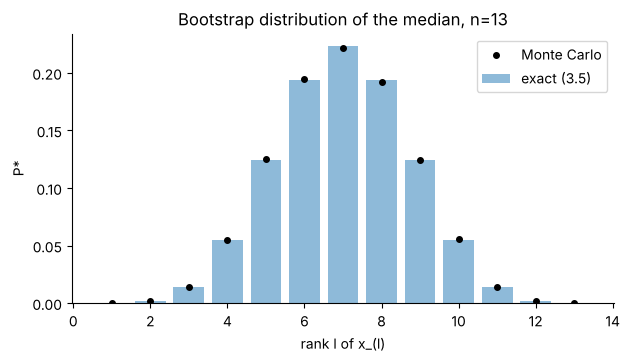

In [6]:
x = np.sort(rng.normal(size=13))
med_star = np.median(rng.choice(x, size=(200000, 13)), axis=1)
emp = np.array([(med_star == v).mean() for v in x])

plt.bar(range(1, 14), p13, alpha=.5, label="exact (3.5)")
plt.plot(range(1, 14), emp, "ko", ms=4, label="Monte Carlo")
plt.xlabel("rank l of x_(l)"); plt.ylabel("P*"); plt.legend(); plt.title("Bootstrap distribution of the median, n=13")
plt.show()

## 4 · Where the jackknife breaks

Paper: $n\,E_*(R^*)^2 \to 1/4f^2(\theta)$ (correct), but
$n\,\widehat{\mathrm{Var}}_{\rm jack} \to \frac{1}{4f^2(\theta)}\,[\chi^2_2/2]^2$, a random limit with mean 2× the truth and variance 20×.

For $N(0,1)$: $1/4f^2(0) = \pi/2 \approx 1.571$.

In [7]:
def boot_var_median(x):
    # exact bootstrap E*(R*)^2 via (3.5)
    xs = np.sort(x); m = (len(x) + 1) // 2
    return np.sum((xs - xs[m-1])**2 * median_boot_probs(len(x)))

def jack_var_median(x):
    n = len(x)
    th = np.array([np.median(np.delete(x, i)) for i in range(n)])
    return (n - 1) / n * np.sum((th - th.mean())**2)

target = np.pi / 2
print(f"{'n':>5} {'n·boot':>10} {'n·jack':>10} {'sd boot':>9} {'sd jack':>9}")
for n in [13, 51, 201, 801]:
    reps = 400 if n < 800 else 150
    b = np.array([n * boot_var_median(rng.normal(size=n)) for _ in range(reps)])
    j = np.array([n * jack_var_median(rng.normal(size=n)) for _ in range(reps)])
    print(f"{n:5d} {b.mean():10.3f} {j.mean():10.3f} {b.std():9.3f} {j.std():9.3f}")
print(f"\ntarget π/2 = {target:.3f}")
print(f"paper's limit (χ²₂/2)²: mean {2*target:.3f}, sd {np.sqrt(20)*target:.3f}")
print(f"(χ²₄/4)²            : mean {1.5*target:.3f}, sd {np.sqrt(5.25)*target:.3f}")

    n     n·boot     n·jack   sd boot   sd jack
   13      2.092      1.829     1.622     2.502


   51      1.905      2.240     0.995     3.239


  201      1.708      2.164     0.610     3.250


  801      1.645      2.187     0.420     2.808

target π/2 = 1.571
paper's limit (χ²₂/2)²: mean 3.142, sd 7.025
(χ²₄/4)²            : mean 2.356, sd 3.599


The bootstrap column settles; the jackknife column stays noisy forever. Why: deleting one point moves the median by at most one order-statistic gap, $O(1/n)$ (Remark J, (8.14)), and for odd $n$ the leave-one-out medians take **only three values**, essentially two clusters separated by $(x_{(m+1)}-x_{(m-1)})/2$. The jackknife sees that one random gap, squared.

**Discrepancy with the paper.** That gap is two consecutive spacings, so $n f\cdot$gap $\to \mathrm{Gamma}(2)$, giving $n\widehat{\mathrm{Var}}_{\rm jack}\,4f^2 \to (\chi^2_4/4)^2$ (mean 1.5, var 5.25), not $(\chi^2_2/2)^2$ (mean 2, var 20). The table above sides with $\chi^2_4$; a direct check at $n=20001$ gave mean 1.50, var 5.5. Inconsistent either way, so the paper's point stands, but the constant looks off, at least for odd $n$ with plain leave-one-out.

In [8]:
x = rng.normal(size=13)
print("distinct leave-one-out medians:", np.unique([np.median(np.delete(x, i)) for i in range(13)]))

distinct leave-one-out medians: [-0.16397083  0.01839211  0.04950372]


## 5 · Rerunning Table 1

$R = |t(\mathbf X) - \theta(F)|/\sigma(F)$, $X_i \sim N(0,1)$, $n=13$. True $E_FR = 0.95$.
Four estimators of $E_FR$ per trial:

- **(3.6)** exact unsmoothed bootstrap
- **(3.10)** exact bootstrap from $\hat F_{\rm SYM}$ (reflect about the median)
- **smoothed (3.11)**: $X^*_i = \bar x + c[x_{I_i} - \bar x + \hat\sigma Z_i]$, $Z\sim U[-d/2,d/2]$, $c=(1+\sigma_Z^2)^{-1/2}$

In [9]:
n, m = 13, 7
true_ER = np.mean(np.abs(np.median(rng.normal(size=(400000, n)), axis=1)))
print(f"E_F R by MC: {true_ER:.4f}   ×√13 = {true_ER*np.sqrt(n):.3f}   (paper: 0.95)")

def sym_probs(n):
    # (3.9): 2n-1 support points z_(1..2n-1)
    m = (n + 1) // 2; L = 2*n - 1; l = np.arange(1, L + 1)
    return stats.binom.cdf(m-1, n, (l-1)/L) - stats.binom.cdf(m-1, n, l/L)

P13, PSYM = median_boot_probs(n), sym_probs(n)

def est_unsmoothed(x):
    xs = np.sort(x); s = x.std()
    return np.sum(np.abs(xs - xs[m-1]) * P13) / s

def est_sym(x):
    xs = np.sort(x); med = xs[m-1]; s = x.std()
    z = np.sort(np.concatenate([xs, 2*med - np.delete(xs, m-1)]))
    return np.sum(np.abs(z - med) * PSYM) / s

def est_smooth(x, d, N=200, kind="unif"):
    xbar, s, med = x.mean(), x.std(), np.median(x)
    I = rng.integers(0, n, size=(N, n))
    if kind == "unif":
        Z = rng.uniform(-d/2, d/2, size=(N, n)); vz = d**2 / 12
    else:  # triangular with var 1/12
        a = np.sqrt(1/2); Z = rng.triangular(-a, 0, a, size=(N, n)); vz = 1/12
    c = (1 + vz) ** -0.5
    Xs = xbar + c * (x[I] - xbar + s * Z)
    return np.mean(np.abs(np.median(Xs, axis=1) - med)) / s

E_F R by MC: 0.2724   ×√13 = 0.982   (paper: 0.95)


In [10]:
trials = 200
cols = ["(3.6)", "(3.10)", "d=0", "d=.25", "d=.5", "d=1", "d=2", "tri"]
out = np.empty((trials, len(cols)))
for t in range(trials):
    x = rng.normal(size=n)
    out[t] = [est_unsmoothed(x), est_sym(x),
              *[est_smooth(x, d) for d in (0, .25, .5, 1, 2)],
              est_smooth(x, None, kind="tri")]

print(" " * 5 + "".join(f"{c:>8}" for c in cols))
print("AVE. " + "".join(f"{v:8.2f}" for v in out.mean(0)))
print("S.D. " + "".join(f"{v:8.2f}" for v in out.std(0)))
print("ratio" + "".join(f"{v:8.2f}" for v in out.mean(0) / true_ER) + "   ← AVE / truth")
print("\npaper (200 trials): AVE 1.01 1.00 1.00 1.01 1.00 .99 .93 | S.D. .31 .33 .32 .32 .32 .30 .26")

        (3.6)  (3.10)     d=0   d=.25    d=.5     d=1     d=2     tri
AVE.     0.27    0.27    0.27    0.28    0.28    0.29    0.31    0.29
S.D.     0.09    0.10    0.09    0.09    0.08    0.07    0.05    0.07
ratio    1.00    1.00    1.00    1.01    1.02    1.06    1.13    1.06   ← AVE / truth

paper (200 trials): AVE 1.01 1.00 1.00 1.01 1.00 .99 .93 | S.D. .31 .33 .32 .32 .32 .30 .26


**Scale.** As literally written, (3.12) has $E_FR\approx 0.27$ at $n=13$, not 0.95. The paper's numbers look like $\sqrt n\,R$ (we get 0.98), but that's a guess, and it doesn't land on 0.95 exactly. The ratio row is scale-free: the paper's is 1.01/0.95 ≈ 1.06.

## Open questions to poke at

1. The paper's estimators run ~6% high; check the ratio row here. Where would bias come from: the bootstrap itself, or $\hat\sigma$ standing in for $\sigma$?
2. Efron guesses the symmetrized version should win when $R$ is asymmetric, e.g. $R=\exp\{X_{(m)}-\theta\}$. Swap $R$ in §5 and test it. (He says "no evidence… at present.")
3. Swap $N(0,1)$ for a skewed $F$ (exponential). Does $\hat F_{\rm SYM}$ now *hurt*?
4. §4: try the **grouped** jackknife with $g \sim \sqrt n$ (Remark J). Does it fix the median?